# 2D Slice of environment and rays

In [3]:
from n23_fluctuations_ragland import tools
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cmocean
import seaborn as sns
import pickle
from dotenv import find_dotenv, load_dotenv
import os
load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'

In [4]:
import matplotlib.font_manager as fm

# Add the font file
font_path = '/Users/john/Library/Fonts/RedHatDisplay-Medium.ttf'  # Update this path
fm.fontManager.addfont(font_path)

# Use the font
plt.rcParams['font.family'] = 'Red Hat Display'

FileNotFoundError: [Errno 2] No such file or directory: '/Users/john/Library/Fonts/RedHatDisplay-Medium.ttf'

In [5]:
dss = tools.open_receptions()

100%|██████████| 23/23 [00:16<00:00,  1.38it/s]


In [6]:
fctd_raw = tools.compute_filtered_fctd_grid(None, None)
fctd_smooth = tools.compute_filtered_fctd_grid(z_smooth=200, r_smooth=15000)

fctd_raw = fctd_raw.assign_coords({'range':(fctd_raw.range.values + 35e3)/1000})
fctd_smooth = fctd_smooth.assign_coords({'range':(fctd_smooth.range.values + 35e3)/1000})

fctd_smooth = fctd_smooth.interpolate_na('depth')

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)


In [7]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/ray_run_forward_back.pkl"

with open(fn, "rb") as f:
    ray_run = pickle.load(f)

rays = ray_run["rays"]
rays_back = ray_run["rays_back"]
eigs = ray_run["eigs"]
eigs_back = ray_run["eigs_back"]
envi = ray_run["envi"]
envi_back = ray_run["envi_back"]

In [13]:
ray_ids_plot = ['-6']

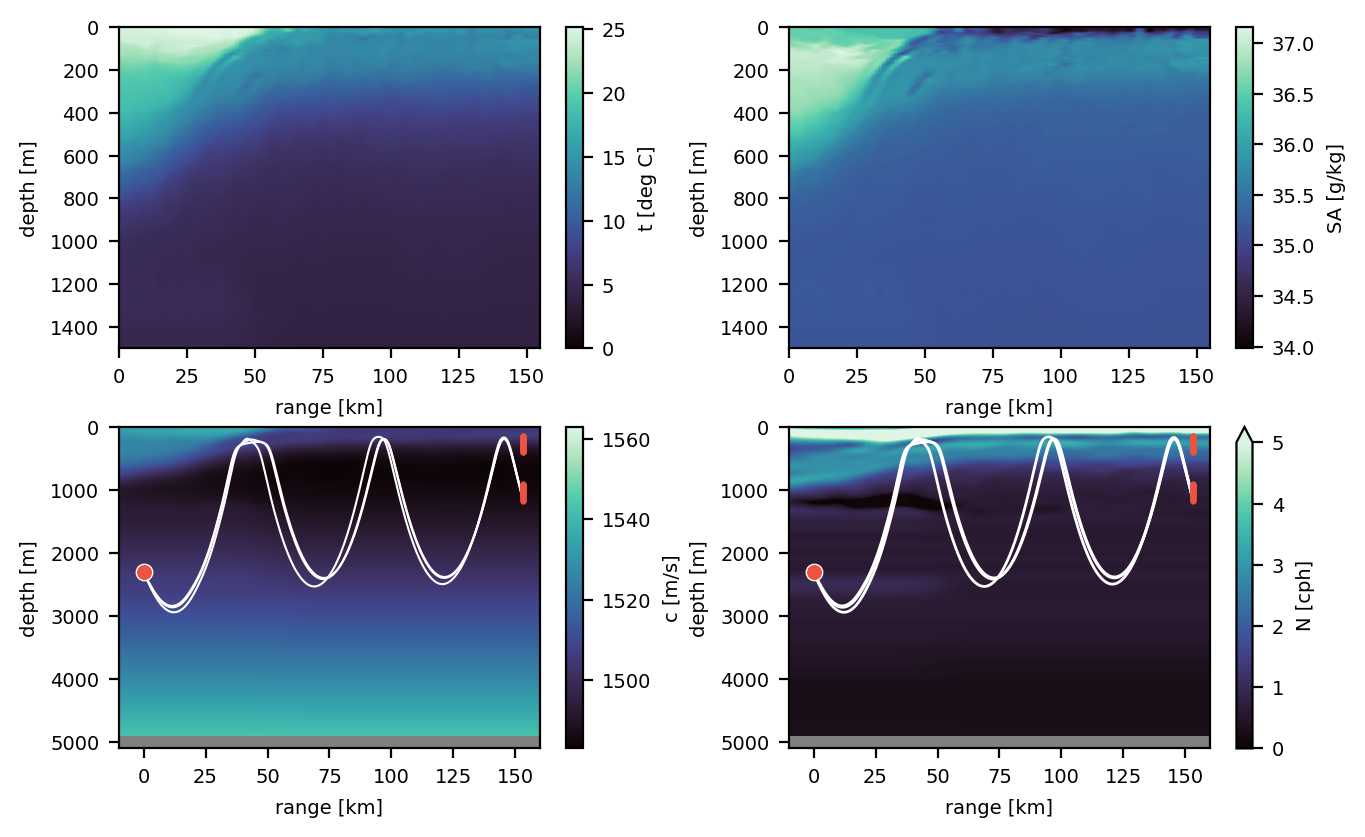

In [14]:
plt.rcParams.update({'font.size':'7'})
plt.rcParams.update({"text.usetex": False})

fig, axes = plt.subplots(2,2, figsize=(6.67, 4))
axes = axes.flatten()

plt.sca(axes[0])
fctd_raw['t'].plot(cmap='mako', vmin=0, rasterized=True)

plt.xlim([0, 155])
plt.ylim([1500,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')


plt.sca(axes[1])
fctd_raw['SA'].plot(cmap='mako', rasterized=True)

plt.xlim([0, 155])
plt.ylim([1500,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

plt.sca(axes[2])
fctd_smooth['c'].plot(cmap='mako', rasterized=True)

for ray_id in ray_ids_plot:
    ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
    for n in range(len(tools.EIG_INDEXS[ray_id])):
        eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][n][0]]
        plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=0.75, alpha=1)
    #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='k', lw=0.5, alpha=1)

plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="#EE5340", lw=0, s=5, zorder=100)
plt.scatter(x=0, y=2300, s=35, lw=0.5, c="#EE5340", edgecolor="w", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

plt.sca(axes[3])
fctd_smooth['N'].plot(cmap='mako', vmin=0, vmax=5, rasterized=True)

for ray_id in ray_ids_plot:
    ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
    for n in range(len(tools.EIG_INDEXS[ray_id])):
        eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][n][0]]
        plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=1, alpha=1)
    #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='k', lw=0.5, alpha=1)

plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="#EE5340", lw=0, s=5, zorder=100)
plt.scatter(x=0, y=2300, s=35, lw=0.5, c="#EE5340", edgecolor="w", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

plt.tight_layout(pad=0)

#plt.savefig('../../figures/presentation_figures/2D_slice.pdf', dpi=300)
#plt.show()45